In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

learn = pd.read_csv("learn.csv", index_col=0)
print("learn:", learn.shape)

learn: (16979, 41)


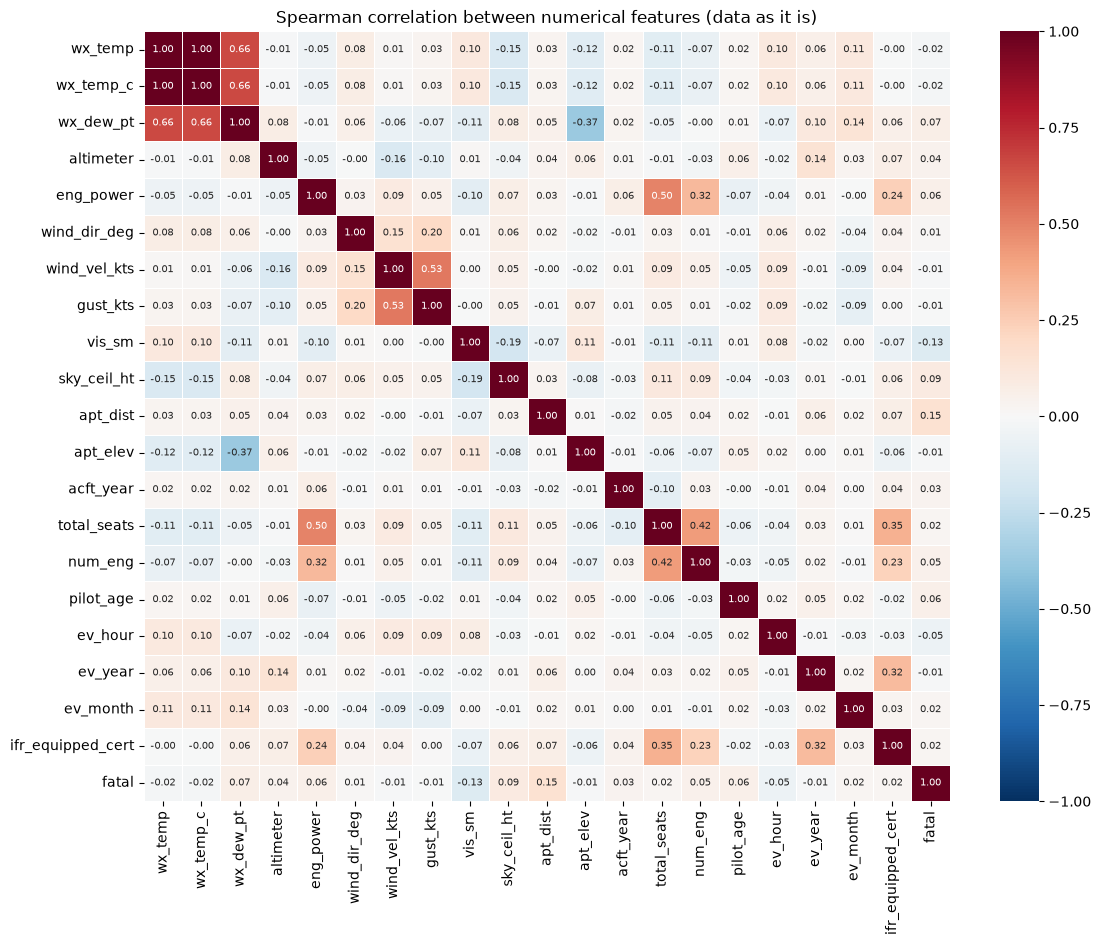

Correlation with fatal (sorted by absolute value):
apt_dist             0.149
vis_sm              -0.135
sky_ceil_ht          0.090
wx_dew_pt            0.066
pilot_age            0.059
eng_power            0.056
ev_hour             -0.055
num_eng              0.052
altimeter            0.040
acft_year            0.033
ifr_equipped_cert    0.023
ev_month             0.023
total_seats          0.022
wx_temp_c           -0.018
wx_temp             -0.018
apt_elev            -0.010
wind_vel_kts        -0.010
wind_dir_deg         0.010
ev_year             -0.008
gust_kts            -0.006
Name: fatal, dtype: float64


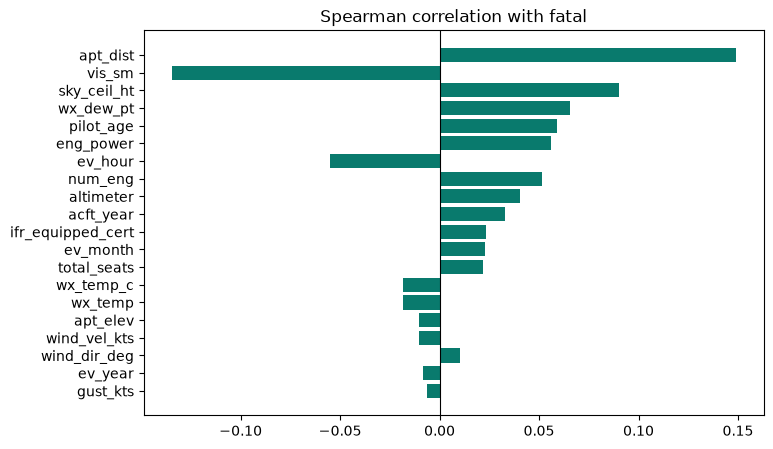


Most dependent pairs (|corr| > 0.5):
wx_temp       wx_temp_c    1.000
              wx_dew_pt    0.661
wx_temp_c     wx_dew_pt    0.661
wind_vel_kts  gust_kts     0.526
dtype: float64


In [2]:
corr_cols = ["wx_temp", "wx_temp_c", "wx_dew_pt", "altimeter", "eng_power", "wind_dir_deg", "wind_vel_kts",
             "gust_kts", "vis_sm", "sky_ceil_ht", "apt_dist", "apt_elev", "acft_year", "total_seats",
             "num_eng", "pilot_age", "ev_hour", "ev_year", "ev_month", "ifr_equipped_cert", "fatal"]

# Spearman because the data is not cleaned yet (outliers would ruin Pearson)
corr = learn[corr_cols].corr(method="spearman")

plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 7}, linewidths=0.5)
plt.title("Spearman correlation between numerical features (data as it is)")
plt.show()

# correlation with the target
target_corr = corr["fatal"].drop("fatal").sort_values(key=abs, ascending=False)
print("Correlation with fatal (sorted by absolute value):")
print(target_corr.round(3))

plt.figure(figsize=(8, 5))
plt.barh(target_corr.index[::-1], target_corr.values[::-1], color="#097a6d")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Spearman correlation with fatal")
plt.show()

# pairs of features that are very dependent
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
pairs = pairs.drop([p for p in pairs.index if "fatal" in p])
print("\nMost dependent pairs (|corr| > 0.5):")
print(pairs[pairs.abs() > 0.5].sort_values(key=abs, ascending=False).round(3))


# IMPORTANTE
## Conclusão do teste de correlações

Teste feito com os dados como estão (sem limpeza), Spearman.

- **Sinal fraco:** nenhuma numérica passa de 0.15 com `fatal`. As mais ligadas são `apt_dist` (+0.15), `vis_sm` (−0.13) e `sky_ceil_ht` (+0.09).
- **Sem relação clara:** wind, gusts, `apt_elev`, `ev_year` e `acft_year` (≈ 0).
- **Redundância:** `wx_temp` e `wx_temp_c` (1.00, logo drop de uma), `wx_temp` e `wx_dew_pt` (0.66), `wind_vel_kts` e `gust_kts` (0.53), `eng_power` e `total_seats` (0.50).
- **Limitação:** os zeros/outliers por limpar distorcem os valores, e Spearman não apanha relações não lineares (`vis_sm`, `sky_ceil_ht`, `apt_dist`, `ev_hour` valem mais do que a correlação mostra).
- **Próximo passo:** repetir depois da limpeza no NB1 e juntar as categóricas.